# Dataset preparation (downloading etc.)

In [1]:
# # downloading data from kaggle

# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("blastchar/telco-customer-churn")

# print("Path to dataset files:", path)

# # After downloading you can copy the dataset here in this folder. 

In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv("churn_telco_data.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# See all columns
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [4]:
# data types of each columns (Note: some columns are int but actually they are categorical. For example, SeniorCitizen is categorical.)
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [5]:
# the type of data of TotalCharges is 'str'. the reason is for some '-' items. So, we change them to numeric. After this, the 
# '-' items will be NaN so we can fill them using a specific method. 

tc = pd.to_numeric(df.TotalCharges, errors='coerce')



In [6]:
df.TotalCharges = pd.to_numeric(df.TotalCharges, errors='coerce')


df[tc.isnull()][['customerID', 'TotalCharges']]

,customerID,TotalCharges
488,4472-LVYGI,NaN
753,3115-CZMZD,NaN
936,5709-LVOEQ,NaN
1082,4367-NUYAO,NaN
1340,1371-DWPAZ,NaN
3331,7644-OMVMY,NaN
3826,3213-VVOLG,NaN
4380,2520-SGTTA,NaN
5218,2923-ARZLG,NaN
6670,4075-WKNIU,NaN


In [8]:
# by the following we can find NaN items. 
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
# filling NaNs with 0 (it is not the best strategy, but is ok for our tutorial.)

df.TotalCharges = df.TotalCharges.fillna(0)

# After, we don't have any NaN in our data frame. 
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [ ]:
# changing Yes and No in churn column into 0 and 1 respectively because ...

df.Churn

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: str

In [11]:
# yes_churns = df.Churn[df.Churn == 'Yes'].index 
# no_churns = df.Churn[df.Churn == "No"].index

# yes_churns

# df.loc[yes_churns, "Churn"] = '1'
# df.loc[no_churns, "Churn"] = '0'

# df.head()['Churn']
# df.Churn = pd.to_numeric(df.Churn)

df.Churn = (df.Churn == "Yes").astype(int)
df.Churn


0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [ ]:
# 

In [ ]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

# Setting up Train, Valid, and Test set

In [12]:

# train, valid, test set

from sklearn.model_selection import train_test_split


df_train_full, df_test = train_test_split(
    df, test_size=0.20, random_state=1)

df_train, df_valid = train_test_split(df_train_full, shuffle=False, test_size=0.25) # Why 0.25? explain!

assert len(df_train) + len(df_valid) + len(df_test) == len(df)

len(df_train), len(df_valid), len(df_test)

(4225, 1409, 1409)

In [13]:
y_train = df_train.Churn.values
y_valid = df_valid.Churn.values
y_test = df_test.Churn.values


In [14]:
# We deliberately delete Churn column from our train, valid, and test to be sure that we don't use them during train. Here Churns are labels for predictions. 

del df_train["Churn"]
del df_valid["Churn"]
del df_test["Churn"]

In [15]:
# The following is not mandatory. But you can do it. 

df_train_full = df_train_full.reset_index(drop=True)
df_train_full.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5442-PPTJY,Male,0,Yes,Yes,12,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,258.35,0
1,6261-RCVNS,Female,0,No,No,42,Yes,No,DSL,Yes,...,Yes,Yes,No,Yes,One year,No,Credit card (automatic),73.90,3160.55,1
2,2176-OSJUV,Male,0,Yes,No,71,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),65.15,4681.75,0
3,6161-ERDGD,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,No,Electronic check,85.45,6300.85,0
4,2364-UFROM,Male,0,No,No,30,Yes,No,DSL,Yes,...,No,Yes,Yes,No,One year,No,Electronic check,70.40,2044.75,0


# EDA: Lets analyse our data more and see some aspect of them. 

In [16]:
# We should check about missing values first. We don't have them here. 

df_train_full.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [17]:
# How many churn: global churn ratio

print(df_train_full.Churn.value_counts(normalize=True))

# You can use the following and it will be the same as above (why?)

print(df_train_full.Churn.mean()) # global churn rate

Churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64
0.26996805111821087


In [18]:
# we have 3 numerical features and others are categorical

df.dtypes # tenure, MonthlyCharges, TotalCharges

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [19]:
# Separate numerical from categorical. 

all_features = list(df.columns)
all_features.remove("Churn") # In this experiment, we use Churn as a label for prediction not as a feature. 
all_features.remove("customerID") # customerID is not a real useful feature. It doesn't tell anything about the customer at all. 
print(all_features)

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = list(set(all_features) - set(numeric_features))
print(categorical_features)

X_train = df_train[numeric_features].values
X_valid = df_valid[numeric_features].values
X_test = df_test[numeric_features].values




['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
['DeviceProtection', 'StreamingTV', 'OnlineSecurity', 'PaymentMethod', 'Contract', 'Dependents', 'gender', 'Partner', 'PhoneService', 'MultipleLines', 'InternetService', 'SeniorCitizen', 'TechSupport', 'StreamingMovies', 'PaperlessBilling', 'OnlineBackup']


In [20]:
# We can check and and be sure about a feature to be categorical using the following. If number of unique was a lot, we should check again. 

df_train_full[categorical_features].nunique()

DeviceProtection    3
StreamingTV         3
OnlineSecurity      3
PaymentMethod       4
Contract            3
Dependents          2
gender              2
Partner             2
PhoneService        2
MultipleLines       3
InternetService     3
SeniorCitizen       2
TechSupport         3
StreamingMovies     3
PaperlessBilling    2
OnlineBackup        3
dtype: int64

In [22]:
# Global churn rate

global_churn_rate = df_train_full.Churn.values.mean()
global_churn_rate

np.float64(0.26996805111821087)

In [23]:
# local churn rate among male customers

male_churn_rate = df_train_full[df_train_full.gender == "Male"].Churn.values.mean()
male_churn_rate

np.float64(0.2632135306553911)

In [24]:
# local churn rate among female customers

female_churn_rate = df_train_full[df_train_full.gender == "Female"].Churn.values.mean()
female_churn_rate

np.float64(0.27682403433476394)

In [25]:
with_partner_churn_rate = df_train_full[df_train_full.Partner == "Yes"].Churn.values.mean()
with_partner_churn_rate

np.float64(0.20503330866025166)

In [26]:
no_partner_churn_rate = df_train_full[df_train_full.Partner == "No"].Churn.values.mean()
no_partner_churn_rate

np.float64(0.3298090040927694)

In [27]:
# Difference (what is the interpretation?)

global_churn_rate - male_churn_rate, global_churn_rate - female_churn_rate, global_churn_rate - with_partner_churn_rate, global_churn_rate - no_partner_churn_rate


(np.float64(0.006754520462819769),
 np.float64(-0.006855983216553063),
 np.float64(0.06493474245795922),
 np.float64(-0.05984095297455855))

In [28]:
# risk ratio

male_churn_rate/global_churn_rate, female_churn_rate/global_churn_rate, with_partner_churn_rate/global_churn_rate, no_partner_churn_rate/global_churn_rate

(np.float64(0.9749802969838747),
 np.float64(1.0253955354648652),
 np.float64(0.7594724924338315),
 np.float64(1.2216593879412643))

In [29]:
# using the power of internal implementations

df_train_full.groupby("gender").Churn.mean()

gender
Female    0.276824
Male      0.263214
Name: Churn, dtype: float64

In [30]:
df_gender_analysis = df_train_full.groupby("gender").Churn.agg(['mean', 'count', 'std', 'var'])
df_gender_analysis['diff'] = df_gender_analysis['mean'] - global_churn_rate
df_gender_analysis['risk'] = df_gender_analysis['mean'] / global_churn_rate
df_gender_analysis

,mean,count,std,var,diff,risk
gender,,,,,,
Female,0.276824,2796,0.447509,0.200264,0.006856,1.025396
Male,0.263214,2838,0.440455,0.194001,-0.006755,0.974980


In [31]:
df_partner_analysis = df_train_full.groupby("Partner").Churn.agg(['mean', 'count', 'std', 'var'])
df_partner_analysis

,mean,count,std,var
Partner,,,,
No,0.329809,2932,0.470224,0.221110
Yes,0.205033,2702,0.403801,0.163055


In [32]:
df_onlineSecurity_analysis = df_train_full.groupby("OnlineSecurity").Churn.agg(['mean', 'count', 'std', 'var'])
df_onlineSecurity_analysis




,mean,count,std,var
OnlineSecurity,,,,
No,0.420921,2801,0.493795,0.243834
No internet service,0.077805,1221,0.267974,0.071810
Yes,0.153226,1612,0.360317,0.129828


In [34]:
# Let's do it for all! For us, it takes a lot of time. But for computers it is less than one milliseconds. 

df_analysis = dict()

for cat in categorical_features:
    df_analysis[cat] = df_train_full.groupby(cat).Churn.agg(['mean', 'count'])
    df_analysis[cat]['diff'] = df_analysis[cat]['mean'] - global_churn_rate
    df_analysis[cat]['risk'] = df_analysis[cat]['mean'] / global_churn_rate

df_analysis['Partner']

,mean,count,diff,risk
Partner,,,,
No,0.329809,2932,0.059841,1.221659
Yes,0.205033,2702,-0.064935,0.759472


In [35]:
# Another way to see the result without creating dictionary

from IPython.display import display

for cat in categorical_features:
    print(cat)
    df_analysis = df_train_full.groupby(cat).Churn.agg(['mean', 'count'])
    df_analysis['diff'] = df_analysis['mean'] - global_churn_rate
    df_analysis['risk'] = df_analysis['mean'] / global_churn_rate
    display(df_analysis)
    print()
    print()

DeviceProtection


,mean,count,diff,risk
DeviceProtection,,,,
No,0.395875,2473,0.125907,1.466379
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.230412,1940,-0.039556,0.853480




StreamingTV


,mean,count,diff,risk
StreamingTV,,,,
No,0.342832,2246,0.072864,1.269897
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.302723,2167,0.032755,1.121328




OnlineSecurity


...

,mean,count,diff,risk
StreamingMovies,,,,
No,0.338906,2213,0.068938,1.255358
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.307273,2200,0.037305,1.138182




PaperlessBilling


,mean,count,diff,risk
PaperlessBilling,,,,
No,0.172071,2313,-0.097897,0.637375
Yes,0.338151,3321,0.068183,1.252560




OnlineBackup


,mean,count,diff,risk
OnlineBackup,,,,
No,0.404323,2498,0.134355,1.497672
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.217232,1915,-0.052736,0.804660


# Mutual information: How to find the importance of categorical features

## Provide mathematical formulation for mutual_info_score. What is its mathematics and importance and its interpretation. Then based on implementation, explain how etc. bla bla bla 
## sklearn compute it in a concrete domain and give its formula etc. Why do we need this before using our model etc. 

In [36]:
from sklearn.metrics import mutual_info_score

mutual_info_score(df_train_full.Contract, df_train_full.Churn)

0.0983203874041556

In [37]:
mutual_info_score(df_train_full.Churn, df_train_full.Contract)

0.0983203874041556

In [38]:
mutual_info_score(df_train_full.Churn, df_train_full.gender)

0.0001174846211139946

In [39]:
sorted_features = []

for cat in categorical_features:
    score = mutual_info_score(df_train_full.Churn, df_train_full[cat])
    sorted_features.append((score, cat))

sorted_features.sort(key=lambda x: x[0], reverse=True)

print(sorted_features)

[(0.0983203874041556, 'Contract'), (0.06308524972985574, 'OnlineSecurity'), (0.06103245991777444, 'TechSupport'), (0.055867945893496467, 'InternetService'), (0.0469234640537918, 'OnlineBackup'), (0.04345286925268559, 'DeviceProtection'), (0.043210027531582915, 'PaymentMethod'), (0.03185333110086085, 'StreamingTV'), (0.03158089669519908, 'StreamingMovies'), (0.01758882715925275, 'PaperlessBilling'), (0.012345815445534689, 'Dependents'), (0.009967689095399745, 'Partner'), (0.009410216144208144, 'SeniorCitizen'), (0.0008574478744731856, 'MultipleLines'), (0.00022871269738296285, 'PhoneService'), (0.0001174846211139946, 'gender')]


In [41]:
# Alternative method

def mutual_info_churn_scores(series):
    return mutual_info_score(df_train_full.Churn, series)

mi = df_train_full[categorical_features].apply(mutual_info_churn_scores)
mi

DeviceProtection    0.043453
StreamingTV         0.031853
OnlineSecurity      0.063085
PaymentMethod       0.043210
Contract            0.098320
Dependents          0.012346
gender              0.000117
Partner             0.009968
PhoneService        0.000229
MultipleLines       0.000857
InternetService     0.055868
SeniorCitizen       0.009410
TechSupport         0.061032
StreamingMovies     0.031581
PaperlessBilling    0.017589
OnlineBackup        0.046923
dtype: float64

In [42]:
mi.sort_values(ascending=False)

Contract            0.098320
OnlineSecurity      0.063085
TechSupport         0.061032
InternetService     0.055868
OnlineBackup        0.046923
DeviceProtection    0.043453
PaymentMethod       0.043210
StreamingTV         0.031853
StreamingMovies     0.031581
PaperlessBilling    0.017589
Dependents          0.012346
Partner             0.009968
SeniorCitizen       0.009410
MultipleLines       0.000857
PhoneService        0.000229
gender              0.000117
dtype: float64

# Feature importance in the case of numerical features: Correlation

## Provide mathematical formulation and explanation for Pearson correlation formula and its interpretation etc. etc.  what does positive and negative mean? 

In [44]:
from sklearn.feature_selection import r_regression

df_train_full.dtypes

r_tenure = r_regression(df_train_full.Churn.values.reshape(-1, 1), df_train_full.tenure.values)
r_monthlyCharges = r_regression(df_train_full.Churn.values.reshape(-1, 1), df_train_full.MonthlyCharges.values)
r_totalCharges = r_regression(df_train_full.Churn.values.reshape(-1, 1), df_train_full.TotalCharges.values)

r_tenure, r_monthlyCharges, r_totalCharges

(array([-0.35188524]), array([0.19680531]), array([-0.19635337]))

In [45]:
# better way

df_train_full[numeric_features].corrwith(df_train_full.Churn)

tenure           -0.351885
MonthlyCharges    0.196805
TotalCharges     -0.196353
dtype: float64

In [46]:
df_train_full[df_train_full.tenure <= 2].Churn.mean()

np.float64(0.5953420669577875)

In [47]:
df_train_full[(df_train_full.tenure > 2) & (df_train_full.tenure <=12)].Churn.mean()

np.float64(0.3994413407821229)

In [48]:
df_train_full[df_train_full.tenure > 12].Churn.mean()

np.float64(0.17634908339788277)

In [49]:
df_train_full.MonthlyCharges.min()


df_train_full[df_train_full.MonthlyCharges < 20].Churn.mean()

np.float64(0.08829568788501027)

In [50]:
df_train_full[df_train_full.MonthlyCharges > 20].Churn.mean()

np.float64(0.28859323028761497)

# One-hot encoding 

In [55]:

from sklearn.feature_extraction import DictVectorizer

In [56]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_features + numeric_features].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_valid[categorical_features + numeric_features].to_dict(orient='records')
X_val = dv.transform(val_dict)


In [57]:
X_train

array([[ 0.,  0.,  1., ...,  0.,  1., 12.],
       [ 0.,  1.,  0., ...,  1.,  0., 42.],
       [ 0.,  0.,  1., ...,  0.,  1., 71.],
       ...,
       [ 1.,  0.,  0., ...,  1.,  0.,  3.],
       [ 0.,  1.,  0., ...,  0.,  1.,  4.],
       [ 0.,  1.,  0., ...,  0.,  1., 13.]], shape=(4225, 45))

In [ ]:
# even though the above method seems good, also bring another method using OneHotEncoder class in sklearn and give the similar code. Which method 
# is better?? 

# Logistic Regression 

## Logistic Regression is similar to linear regression but we use sigmoid at the end. Explain it more. Provide mathematical formulation for logistic regression. give some examples etc. 

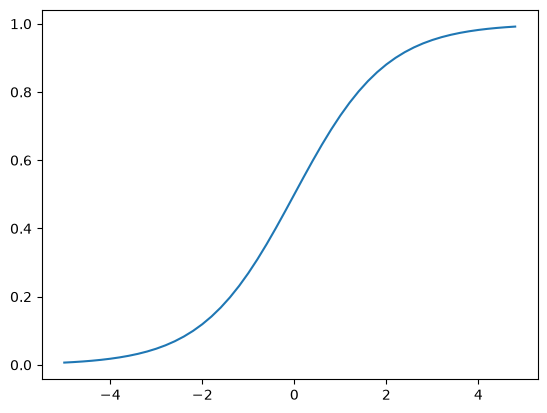

In [54]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

import matplotlib.pyplot as plt

t = np.arange(-5., 5., 0.2)

plt.plot(t, sigmoid(t))
plt.show()

In [58]:
from sklearn.linear_model import LogisticRegression

print(X_train.shape, y_train.shape)

model = LogisticRegression(random_state=1, max_iter=90).fit(X_train, y_train)

# print(X_train[:10, :])

# print(model.predict(X_train[:10, :]))

# print(y_train[:10])

model.score(X_val, y_valid)

(4225, 45) (4225,)


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 90 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=90).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7955997161107168

In [65]:
# lets find the probality of churn. actually it gives us two 
model.predict_proba(X_val)

array([[0.89473062, 0.10526938],
       [0.84556436, 0.15443564],
       [0.98031787, 0.01968213],
       ...,
       [0.37539962, 0.62460038],
       [0.57966141, 0.42033859],
       [0.94216211, 0.05783789]], shape=(1409, 2))

In [66]:
# We consider the second one. 
y_pred_prob = model.predict_proba(X_val)[:, 1]
y_pred_prob

array([0.10526938, 0.15443564, 0.01968213, ..., 0.62460038, 0.42033859,
       0.05783789], shape=(1409,))

In [67]:
y_pred = model.predict(X_val)
y_pred

array([0, 0, 0, ..., 1, 0, 0], shape=(1409,))

In [68]:
churn_customers = df_valid[y_pred==1].customerID
churn_customers

371     0259-GBZSH
3424    4112-LUEIZ
1538    6326-MTTXK
4335    9208-OLGAQ
5186    3776-EKTKM
           ...    
5374    8065-YKXKD
3462    3834-XUIFC
2797    6023-YEBUP
905     0781-LKXBR
3980    8868-WOZGU
Name: customerID, Length: 322, dtype: str

In [70]:
# How many customers are likely to leave us. 
len(churn_customers)

322

In [71]:
# weights
model.coef_[0]

array([ 5.01718770e-01, -2.14499124e-01, -4.26603498e-01, -2.14430740e-02,
       -1.17940778e-01,  1.43481141e-02, -1.03263377e-01, -5.04685897e-02,
       -3.61170810e-01,  3.25050334e-01, -1.03263377e-01,  4.39433173e-03,
       -2.04082122e-01,  8.71071088e-02, -2.24088392e-02,  1.34419103e-01,
       -1.03263377e-01, -1.70539579e-01,  2.29002186e-01, -1.03263377e-01,
       -2.65122662e-01, -2.44909391e-01,  1.05525539e-01, -1.38679700e-01,
       -7.04151754e-04, -3.11878462e-02, -1.19056442e-01,  1.64011439e-01,
       -1.53151003e-01,  8.71071088e-02, -2.26490961e-01,  1.80876368e-01,
       -1.79466029e-01, -1.03263377e-01,  1.43345553e-01, -7.92630943e-02,
       -1.03263377e-01,  4.31426187e-02,  2.22512871e-01, -1.03263377e-01,
       -2.58633346e-01,  2.40503600e-04, -8.51252138e-02, -5.42586384e-02,
       -5.64556872e-02])

In [72]:
# bias term. It shows .... 

model.intercept_

array([-0.14120108])

In [73]:
# Model interpretation 

dv.get_feature_names_out()

array(['Contract=Month-to-month', 'Contract=One year',
       'Contract=Two year', 'Dependents=No', 'Dependents=Yes',
       'DeviceProtection=No', 'DeviceProtection=No internet service',
       'DeviceProtection=Yes', 'InternetService=DSL',
       'InternetService=Fiber optic', 'InternetService=No',
       'MonthlyCharges', 'MultipleLines=No',
       'MultipleLines=No phone service', 'MultipleLines=Yes',
       'OnlineBackup=No', 'OnlineBackup=No internet service',
       'OnlineBackup=Yes', 'OnlineSecurity=No',
       'OnlineSecurity=No internet service', 'OnlineSecurity=Yes',
       'PaperlessBilling=No', 'PaperlessBilling=Yes', 'Partner=No',
       'Partner=Yes', 'PaymentMethod=Bank transfer (automatic)',
       'PaymentMethod=Credit card (automatic)',
       'PaymentMethod=Electronic check', 'PaymentMethod=Mailed check',
       'PhoneService=No', 'PhoneService=Yes', 'SeniorCitizen',
       'StreamingMovies=No', 'StreamingMovies=No internet service',
       'StreamingMovies=Yes', '

In [76]:
# some assertion (they should be the same because .... )
len(dv.get_feature_names_out()), len(model.coef_[0])

(45, 45)

In [77]:
feature_weights = dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))
feature_weights

{'Contract=Month-to-month': np.float64(0.502),
 'Contract=One year': np.float64(-0.214),
 'Contract=Two year': np.float64(-0.427),
 'Dependents=No': np.float64(-0.021),
 'Dependents=Yes': np.float64(-0.118),
 'DeviceProtection=No': np.float64(0.014),
 'DeviceProtection=No internet service': np.float64(-0.103),
 'DeviceProtection=Yes': np.float64(-0.05),
 'InternetService=DSL': np.float64(-0.361),
 'InternetService=Fiber optic': np.float64(0.325),
 'InternetService=No': np.float64(-0.103),
 'MonthlyCharges': np.float64(0.004),
 'MultipleLines=No': np.float64(-0.204),
 'MultipleLines=No phone service': np.float64(0.087),
 'MultipleLines=Yes': np.float64(-0.022),
 'OnlineBackup=No': np.float64(0.134),
 'OnlineBackup=No internet service': np.float64(-0.103),
 'OnlineBackup=Yes': np.float64(-0.171),
 'OnlineSecurity=No': np.float64(0.229),
 'OnlineSecurity=No internet service': np.float64(-0.103),
 'OnlineSecurity=Yes': np.float64(-0.265),
 'PaperlessBilling=No': np.float64(-0.245),
 'Paper

In [78]:
# Let's consider a simpler model to see and interpret the weights

df_train_full

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5442-PPTJY,Male,0,Yes,Yes,12,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,258.35,0
1,6261-RCVNS,Female,0,No,No,42,Yes,No,DSL,Yes,...,Yes,Yes,No,Yes,One year,No,Credit card (automatic),73.90,3160.55,1
2,2176-OSJUV,Male,0,Yes,No,71,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),65.15,4681.75,0
3,6161-ERDGD,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,No,Electronic check,85.45,6300.85,0
4,2364-UFROM,Male,0,No,No,30,Yes,No,DSL,Yes,...,No,Yes,Yes,No,One year,No,Electronic check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781-LKXBR,Male,1,No,No,9,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.50,918.60,1
5630,3507-GASNP,Male,0,No,Yes,60,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.95,1189.90,0
5631,8868-WOZGU,Male,0,No,No,28,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,105.70,2979.50,1
5632,1251-KRREG,Male,0,No,No,2,Yes,Yes,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,54.40,114.10,1


In [79]:
dv_small = DictVectorizer(sparse=False)

train_dict_small = df_train[['Contract', 'MonthlyCharges', 'tenure']].to_dict(orient='records')
X_train_small = dv_small.fit_transform(train_dict_small)

val_dict_small = df_valid[['Contract', 'MonthlyCharges', 'tenure']].to_dict(orient='records')
X_val_small = dv_small.transform(val_dict_small)


model_small = LogisticRegression()

model_small.fit(X_train_small, y_train)

model_small.coef_[0]

array([ 1.01559435, -0.04781801, -0.97353748,  0.02882832, -0.03692212])

In [80]:
list(zip(dv_small.get_feature_names_out(), model_small.coef_[0].round(3)))

[('Contract=Month-to-month', np.float64(1.016)),
 ('Contract=One year', np.float64(-0.048)),
 ('Contract=Two year', np.float64(-0.974)),
 ('MonthlyCharges', np.float64(0.029)),
 ('tenure', np.float64(-0.037))]

In [81]:
model_small.intercept_

array([-2.58035383])

In [82]:
# Now we can interpret each of these numbers. It shows ..... You can bring more analysis here. also, some graphs visualization etc. 

sigmoid(-2.58 + 1.016 + 50 * 0.029 + 4 * (-0.037)) 

np.float64(0.4348721276091598)

# Using the model

In [83]:
# Current model use the df_train. But it is better that we consider df_train_full (which  has both train and valid) and then 
# check the result on test set. 
model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",90
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the

In [84]:
df_train_full.isna().sum()

print(len(df_train_full[categorical_features + numeric_features].to_dict(orient='records')))

5634


In [85]:
# Let's consider the full train dataset. Note that the validation 


df_train_full.columns

y_train_full = df_train_full.Churn.values
y_train_full

dv_full = DictVectorizer(sparse=False)
print(len(df_train_full))

train_dict_full = df_train_full[categorical_features + numeric_features].to_dict(orient='records')
X_train_full = dv_full.fit_transform(train_dict_full)

test_dict = df_test[categorical_features + numeric_features].to_dict(orient='records')
X_test = dv_full.transform(test_dict)

X_train_full.shape, y_train_full.shape, X_test.shape, y_test.shape

# df_train.columns

5634


((5634, 45), (5634,), (1409, 45), (1409,))

In [ ]:
# We can increase the max_iter for converges. 

model_full = LogisticRegression(max_iter=5000)
model_full.fit(X_train_full, y_train_full)



,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [87]:
model_full.coef_

array([[ 6.73380664e-01,  2.82640544e-02, -7.23068296e-01,
         2.11688191e-02, -4.25923947e-02,  8.25131759e-02,
        -1.54726198e-01,  5.07894458e-02, -4.62688081e-01,
         5.95990703e-01, -1.54726198e-01, -1.21298602e-02,
        -1.72976351e-01,  3.79873529e-02,  1.13565422e-01,
         1.29486346e-01, -1.54726198e-01,  3.81627602e-03,
         2.28512645e-01, -1.54726198e-01, -9.52100236e-02,
        -1.73369529e-01,  1.51945953e-01, -2.79422440e-02,
         6.51866870e-03, -6.26733547e-02, -8.77732107e-02,
         2.34710868e-01, -1.05687878e-01,  3.79873529e-02,
        -5.94109285e-02,  1.91823912e-01, -1.13703142e-01,
        -1.54726198e-01,  2.47005764e-01, -6.00545532e-02,
        -1.54726198e-01,  1.93357175e-01,  2.13333278e-01,
        -1.54726198e-01, -8.00306560e-02,  3.44217542e-04,
         4.13348041e-03, -2.55570560e-02, -6.20406989e-02]])

In [88]:
model_full.predict_proba(X_test)

array([[0.93246657, 0.06753343],
       [0.90502017, 0.09497983],
       [0.66509172, 0.33490828],
       ...,
       [0.99483742, 0.00516258],
       [0.79655463, 0.20344537],
       [0.35956054, 0.64043946]], shape=(1409, 2))

In [89]:
model_full.score(X_test, y_test)
# model_full.score(X_train_full, y_train_full)

0.8119233498935415

In [91]:
# Let's find the customers that they are going to leave us likely. 
churn_customers = df_test[model_full.predict(X_test)>0].customerID

churn_customers, len(churn_customers), len(df_test), len(churn_customers)/len(df_test) * 100

(5368    6168-WFVVF
 4673    6402-ZFPPI
 4719    0362-ZBZWJ
 2364    4559-UWIHT
 288     3488-PGMQJ
            ...    
 4837    5134-IKDAY
 4531    4910-AQFFX
 6912    2215-ZAFGX
 2563    5130-IEKQT
 5154    9874-QLCLH
 Name: customerID, Length: 325, dtype: str,
 325,
 1409,
 23.066004258339248)

In [92]:
churn_customers.values

<StringArray>
['6168-WFVVF', '6402-ZFPPI', '0362-ZBZWJ', '4559-UWIHT', '3488-PGMQJ',
 '1342-JPNKI', '2897-DOVND', '8699-ASUFO', '3006-XIMLN', '1894-IGFSG',
 ...
 '8225-BTJAU', '7703-ZEKEF', '0337-CNPZE', '0947-IDHRQ', '1157-BQCUW',
 '5134-IKDAY', '4910-AQFFX', '2215-ZAFGX', '5130-IEKQT', '9874-QLCLH']
Length: 325, dtype: str

In [93]:
# We can send them a gift to prevent them from churning. 

for customer in churn_customers:
    # create an email and send them a gift to stay with us! but don't say the reason of gift. 
    print(f'hello dear {customer} we want to give you a gift without any reason!')

hello dear 6168-WFVVF we want to give you a gift without any reason!
hello dear 6402-ZFPPI we want to give you a gift without any reason!
hello dear 0362-ZBZWJ we want to give you a gift without any reason!
hello dear 4559-UWIHT we want to give you a gift without any reason!
hello dear 3488-PGMQJ we want to give you a gift without any reason!
hello dear 1342-JPNKI we want to give you a gift without any reason!
hello dear 2897-DOVND we want to give you a gift without any reason!
hello dear 8699-ASUFO we want to give you a gift without any reason!
hello dear 3006-XIMLN we want to give you a gift without any reason!
hello dear 1894-IGFSG we want to give you a gift without any reason!
hello dear 0880-TKATG we want to give you a gift without any reason!
hello dear 3990-QYKBE we want to give you a gift without any reason!
hello dear 8456-QDAVC we want to give you a gift without any reason!
hello dear 1853-UDXBW we want to give you a gift without any reason!
hello dear 9274-CNFMO we want to g

In [95]:
# Check for a specific customer. A more realistic scenario. 

customer = test_dict[10]
customer



{'DeviceProtection': 'No',
 'StreamingTV': 'Yes',
 'OnlineSecurity': 'No',
 'PaymentMethod': 'Mailed check',
 'Contract': 'Month-to-month',
 'Dependents': 'Yes',
 'gender': 'Male',
 'Partner': 'Yes',
 'PhoneService': 'Yes',
 'MultipleLines': 'No',
 'InternetService': 'Fiber optic',
 'SeniorCitizen': 1,
 'TechSupport': 'No',
 'StreamingMovies': 'Yes',
 'PaperlessBilling': 'Yes',
 'OnlineBackup': 'Yes',
 'tenure': 32,
 'MonthlyCharges': 93.95,
 'TotalCharges': 2861.45}

In [96]:
# We need to convert the dict into feature vector because the input of our model is feature vector not a dictionary. 
customer_features = dv_full.transform([customer])
customer_features



array([[1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        1.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 9.39500e+01, 1.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 1.00000e+00, 1.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 1.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00, 0.00000e+00,
        1.00000e+00, 1.00000e+00, 0.00000e+00, 0.00000e+00, 1.00000e+00,
        0.00000e+00, 0.00000e+00, 1.00000e+00, 1.00000e+00, 0.00000e+00,
        0.00000e+00, 2.86145e+03, 0.00000e+00, 1.00000e+00, 3.20000e+01]])

In [98]:
# checking
customer_features.shape

(1, 45)

In [99]:
model_full.predict_proba(customer_features)[0, 1]

np.float64(0.4802053058511076)

In [101]:
# with another model
model.predict_proba(customer_features)[0, 1]

np.float64(0.4979021484173131)

In [ ]:
y_test[10]

np.int64(0)

In [ ]:
y_test[-1]

np.int64(1)

In [ ]:
# Check for a specific customer 

customer_2 = test_dict[-1]
customer_2_features = dv_full.transform([customer])
model_full.predict_proba(customer_2_features)

array([[0.51979469, 0.48020531]])

# Use perceptron instead of logistic regression for this task